# Pronóstico de caudal – Cuenca del Gualeguaychú

Calcula, a partir de un **CSV de precipitación horaria pronosticada** (grilla lat/lon) y de la capa de **subcuencas HydroSHEDS nivel 12**:

1. la **lámina de lluvia horaria (mm) de cada subcuenca**,
2. la lluvia efectiva (SCS-CN) y el hidrograma de cada subcuenca con su **Tc**,
3. el tránsito por la red hasta el **punto más bajo de descarga** (usa `NEXT_DOWN` y `DIST_SINK` de HydroSHEDS),
4. el hidrograma total en la salida (suma de aportes + caudal base).

**Cómo usarlo:** ejecutá las celdas en orden (*Entorno → Ejecutar todo*). Ajustá los parámetros en la celda 2 y subí los archivos cuando se pida. Al final se descarga un `.zip` con el Excel, las figuras y la capa para QGIS.

> El Tc se estima con fórmula (Kirpich/Témez) si no se cargan valores propios. Para usar los propios: corré una vez, editá `Tc_h` y `CN` en la hoja `Parametros_subcuencas` del Excel y volvé a cargarlo marcando *usar_parametros*.

In [ ]:
# 1) Librerías (Colab ya trae casi todo; geopandas se instala si falta)
try:
    import geopandas as gpd
except ImportError:
    !pip install -q geopandas
    import geopandas as gpd
!pip install -q openpyxl

import os, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

In [ ]:
# 2) Parámetros del modelo
cn_def = 95            #@param {type:"number"}
metodo_tc = "Kirpich"  #@param ["Kirpich", "Temez"]
pendiente = 0.002      #@param {type:"number"}
velocidad = 1.0        #@param {type:"number"}
q_base = 5.0           #@param {type:"number"}
ia_ratio = 0.2         #@param {type:"number"}
usar_parametros = False #@param {type:"boolean"}

# cn_def     : CN por defecto (AMC II) para subcuencas sin CN propio
# metodo_tc  : fórmula de Tc si no se carga Tc propio (L = 1.4*A^0.6 km)
# pendiente  : pendiente media del cauce [m/m], para la fórmula de Tc
# velocidad  : velocidad de traslado en el cauce [m/s] (tránsito por DIST_SINK)
# q_base     : caudal base [m3/s]
# ia_ratio   : abstracción inicial Ia = ia_ratio * S

In [ ]:
# 3) Funciones del modelo
def leer_csv_pronostico(archivos):
    """Devuelve (lon, lat, matriz[npuntos, ntiempos], tiempos)."""
    partes = []
    for archivo in sorted(archivos):
        d = pd.read_csv(archivo, encoding="utf-8-sig")
        d.columns = [c.strip().lower() for c in d.columns]
        falt = {"latitud", "longitud", "fecha_hora_pronostico", "precipitacion_mm"} - set(d.columns)
        if falt:
            raise ValueError(f"{os.path.basename(archivo)}: faltan columnas {sorted(falt)}")
        d["fecha_hora_pronostico"] = pd.to_datetime(d["fecha_hora_pronostico"])
        partes.append(d[["latitud", "longitud", "fecha_hora_pronostico", "precipitacion_mm"]])
    d = pd.concat(partes, ignore_index=True)
    d["precipitacion_mm"] = pd.to_numeric(d["precipitacion_mm"], errors="coerce").clip(lower=0)
    d = d.drop_duplicates(["latitud", "longitud", "fecha_hora_pronostico"], keep="last")
    tabla = d.pivot_table(index=["latitud", "longitud"], columns="fecha_hora_pronostico",
                          values="precipitacion_mm", aggfunc="mean").sort_index(axis=1)
    lat = tabla.index.get_level_values(0).values
    lon = tabla.index.get_level_values(1).values
    return lon, lat, tabla.values, tabla.columns


def leer_capa(ruta):
    """Lee shp / gpkg / geojson, o un .zip con el shapefile."""
    if ruta.lower().endswith(".zip"):
        return gpd.read_file("zip://" + ruta)
    return gpd.read_file(ruta)


def leer_parametros(ruta):
    """Archivo opcional con HYBAS_ID (o ID), Tc_h y/o CN. Devuelve DataFrame indexado por ID (str)."""
    if ruta.lower().endswith((".xlsx", ".xls")):
        hojas = pd.ExcelFile(ruta).sheet_names
        hoja = "Parametros_subcuencas" if "Parametros_subcuencas" in hojas else hojas[0]
        d = pd.read_excel(ruta, sheet_name=hoja, dtype=str)
    else:
        d = pd.read_csv(ruta, sep=None, engine="python", dtype=str, encoding="utf-8-sig")
    d.columns = [c.strip().lower() for c in d.columns]
    c_id = next((c for c in ("hybas_id", "id") if c in d.columns), None)
    if c_id is None:
        raise ValueError("El archivo de parámetros necesita una columna HYBAS_ID (o ID).")
    out = pd.DataFrame(index=d[c_id].astype(str).str.strip().str.replace(r"\.0$", "", regex=True))
    for col, nombre in (("tc_h", "Tc_h"), ("cn", "CN")):
        if col in d.columns:
            out[nombre] = pd.to_numeric(d[col].str.replace(",", "."), errors="coerce").values
    return out


# --------------------------------------------------------------------------
# Lámina media por subcuenca
# --------------------------------------------------------------------------
def puntos_en_poligono(geom, paso=0.02):
    """Puntos de una grilla regular (paso en grados, ~2 km) dentro del polígono."""
    minx, miny, maxx, maxy = geom.bounds
    xs = np.arange(minx + paso / 2, maxx, paso)
    ys = np.arange(miny + paso / 2, maxy, paso)
    X, Y = np.meshgrid(xs, ys)
    X, Y = X.ravel(), Y.ravel()
    try:
        import shapely
        dentro = shapely.contains_xy(geom, X, Y)
    except AttributeError:  # shapely 1.x
        from shapely import vectorized
        dentro = vectorized.contains(geom, X, Y)
    pts = np.column_stack([X[dentro], Y[dentro]])
    if len(pts) == 0:  # subcuenca más chica que la malla
        p = geom.representative_point()
        pts = np.array([[p.x, p.y]])
    return pts


def interpolar_idw(P, V, S, k=4, pot=2.0):
    """Inverso de la distancia con los k vecinos más cercanos (solo numpy).
    P[n,2]=(lon,lat) de los puntos, V[n,nt] valores, S[m,2] puntos a estimar."""
    f = np.cos(np.deg2rad(P[:, 1].mean()))  # corrige la longitud por la latitud
    dx = (S[:, None, 0] - P[None, :, 0]) * f
    dy = S[:, None, 1] - P[None, :, 1]
    d2 = dx * dx + dy * dy
    k = min(k, P.shape[0])
    idx = np.argpartition(d2, k - 1, axis=1)[:, :k]
    dk = np.take_along_axis(d2, idx, axis=1)
    w = 1.0 / np.maximum(dk, 1e-12) ** (pot / 2.0)
    w /= w.sum(axis=1, keepdims=True)
    return np.einsum("mk,mkt->mt", w, V[idx])


def lamina_por_subcuenca(gdf_wgs84, lon, lat, matriz):
    """Lámina media (mm) por hora y subcuenca. Array [ntiempos, nsubcuencas]."""
    P = np.column_stack([lon, lat])
    V = np.nan_to_num(matriz, nan=0.0)
    out = np.zeros((V.shape[1], len(gdf_wgs84)))
    for k, geom in enumerate(gdf_wgs84.geometry):
        S = puntos_en_poligono(geom)
        out[:, k] = np.clip(interpolar_idw(P, V, S), 0, None).mean(axis=0)
    return out


# --------------------------------------------------------------------------
# Parámetros de subcuencas y modelo hidrológico
# --------------------------------------------------------------------------
def buscar_columna(gdf, candidatos):
    cols = {c.lower(): c for c in gdf.columns}
    for c in candidatos:
        if c.lower() in cols:
            return cols[c.lower()]
    return None


def tc_formula(area_km2, metodo, pend):
    """Tc (h) con L = 1.4*A^0.6 km (Hack) y pendiente media del cauce (m/m)."""
    L = 1.4 * np.power(area_km2, 0.6)  # km
    if metodo == "Temez":
        return 0.3 * (L / pend ** 0.25) ** 0.76
    return 0.0195 * (L * 1000.0) ** 0.77 * pend ** -0.385 / 60.0  # Kirpich


def preparar_subcuencas(gdf, cn_def, vel_ms, metodo_tc, pend, df_param=None):
    """DataFrame con ID, Area_km2, Tc_h, Tv_h, CN, Es_salida (una fila por subcuenca)."""
    gdf = gdf.reset_index(drop=True).copy()
    gm = gdf.to_crs(epsg=6933)  # áreas iguales, en metros

    c_id = buscar_columna(gdf, ["HYBAS_ID", "ID"])
    ids = gdf[c_id].astype(str) if c_id else pd.Series(gdf.index.astype(str))

    c_a = buscar_columna(gdf, ["SUB_AREA", "Area_km2"])
    area = gdf[c_a].astype(float) if c_a else gm.geometry.area / 1e6

    # --- Tc
    tc = pd.Series(tc_formula(area.values, metodo_tc, pend), index=gdf.index)
    c_tc = buscar_columna(gdf, ["Tc_h"])
    if c_tc:
        tc = gdf[c_tc].astype(float).fillna(tc)
    cn = pd.Series(cn_def, index=gdf.index, dtype=float)
    c_cn = buscar_columna(gdf, ["CN"])
    if c_cn:
        cn = gdf[c_cn].astype(float).fillna(cn)
    if df_param is not None:
        if "Tc_h" in df_param:
            tc = ids.map(df_param["Tc_h"]).astype(float).fillna(tc)
        if "CN" in df_param:
            cn = ids.map(df_param["CN"]).astype(float).fillna(cn)

    # --- Tránsito a la salida y punto de descarga
    c_nd = buscar_columna(gdf, ["NEXT_DOWN"])
    c_ds = buscar_columna(gdf, ["DIST_SINK", "DIST_MAIN"])
    c_up = buscar_columna(gdf, ["UP_AREA"])
    if c_nd:
        es_salida = ~gdf[c_nd].astype(str).isin(set(ids))
        if es_salida.sum() != 1:  # varias salidas: la de mayor área aportante
            ref = gdf[c_up] if c_up else area
            es_salida = pd.Series(False, index=gdf.index)
            es_salida[ref.idxmax()] = True
    else:
        es_salida = pd.Series(False, index=gdf.index)
        es_salida[gm.geometry.centroid.y.idxmin()] = True  # sin topología: la más al sur

    if c_ds:
        tv = gdf[c_ds].astype(float) * 1000.0 / vel_ms / 3600.0
    else:
        cen = gm.geometry.centroid
        i_sal = es_salida.idxmax()
        tv = cen.distance(cen[i_sal]) * 1.3 / vel_ms / 3600.0

    subc = pd.DataFrame({"ID": ids.values, "Area_km2": area.values, "Tc_h": tc.values,
                         "Tv_h": tv.values, "CN": cn.values, "Es_salida": es_salida.values})
    if c_up:
        subc["Area_aportante_km2"] = gdf[c_up].values
    return subc, gdf


def lluvia_efectiva_scs(p_inc, cn, ia_ratio=0.2):
    """Lluvia efectiva incremental (mm) con SCS-CN sobre la precipitación acumulada."""
    s = 25400.0 / cn - 254.0
    ia = ia_ratio * s
    pc = np.cumsum(p_inc)
    pec = np.where(pc > ia, (pc - ia) ** 2 / (pc - ia + s), 0.0)
    return np.diff(np.concatenate([[0.0], pec]))


def hu_triangular_scs(area_km2, tc_h, dt=1.0):
    """HU (m3/s por mm de lluvia efectiva en dt horas), paso horario."""
    tp = dt / 2.0 + 0.6 * tc_h
    tb = 2.67 * tp
    n = int(np.ceil(tb / dt)) + 1
    t = (np.arange(n) + 1) * dt
    u = np.where(t <= tp, t / tp, np.maximum((tb - t) / (tb - tp), 0.0))
    vol_m3 = area_km2 * 1e3  # 1 mm sobre el área
    return u * vol_m3 / (3600.0 * dt * u.sum())


def calcular(archivos_csv, ruta_subc, cn_def, vel, qbase, ia_ratio,
             metodo_tc="Kirpich", pend=0.002, ruta_param=None):
    """Núcleo del cálculo. Devuelve un diccionario con todos los resultados."""
    df_param = leer_parametros(ruta_param) if ruta_param else None
    subc, gdf = preparar_subcuencas(leer_capa(ruta_subc), cn_def, vel, metodo_tc, pend, df_param)
    gdf84 = gdf.to_crs(epsg=4326)

    # 1) Lámina horaria por subcuenca
    lon, lat, matriz, tiempos = leer_csv_pronostico(archivos_csv)
    lam = lamina_por_subcuenca(gdf84, lon, lat, matriz)
    lluvia = pd.DataFrame(lam, index=pd.DatetimeIndex(tiempos), columns=subc["ID"])
    full = pd.date_range(lluvia.index.min(), lluvia.index.max(), freq="h")
    faltan = len(full) - len(lluvia)
    lluvia = lluvia.reindex(full).fillna(0.0)
    lluvia.index.name = "Fecha_hora"

    # 2-4) Lluvia efectiva, hidrograma propio y tránsito hasta el punto de descarga
    nT = len(lluvia)
    cola = int(np.ceil(subc["Tv_h"].max() + 2.67 * (0.5 + 0.6 * subc["Tc_h"].max()))) + 3
    nTot = nT + cola
    idx_tot = pd.date_range(lluvia.index.min(), periods=nTot, freq="h")

    pe_df = pd.DataFrame(0.0, index=lluvia.index, columns=subc["ID"])
    q_sub = pd.DataFrame(0.0, index=idx_tot, columns=subc["ID"])
    for _, r in subc.iterrows():
        pe = lluvia_efectiva_scs(lluvia[r["ID"]].values, r["CN"], ia_ratio)
        pe_df[r["ID"]] = pe
        q = np.convolve(pe, hu_triangular_scs(r["Area_km2"], r["Tc_h"]))
        d = int(round(r["Tv_h"]))
        n = min(len(q), nTot - d)
        if n > 0:
            q_sub.iloc[d:d + n, q_sub.columns.get_loc(r["ID"])] = q[:n]

    # 5) Integración en el punto más bajo
    q_sal = q_sub.sum(axis=1) + qbase
    q_sal.name = "Q_salida_m3s"
    pesos = subc.set_index("ID")["Area_km2"]
    lluvia_media = (lluvia * pesos).sum(axis=1) / pesos.sum()

    return dict(subc=subc, gdf84=gdf84, lluvia=lluvia, pe=pe_df, q_sub=q_sub,
                q_sal=q_sal, lluvia_media=lluvia_media, faltan=faltan,
                salida_id=subc.loc[subc["Es_salida"], "ID"].iloc[0])


In [ ]:
# 4) Cargar archivos
print("1) Subí la capa de subcuencas: el .zip con el shapefile (subcuencas_hydrosheds_n12.zip)")
up = files.upload()
ruta_subc = next(iter(up))

print("\n2) Subí uno o más CSV de pronóstico de precipitación")
up = files.upload()
archivos_csv = list(up.keys())

ruta_param = None
if usar_parametros:
    print("\n3) Subí el archivo de Tc/CN por subcuenca (.xlsx o .csv)")
    up = files.upload()
    ruta_param = next(iter(up))

print("\nSubcuencas:", ruta_subc, "| CSV:", archivos_csv, "| Parámetros:", ruta_param)

1) Subí la capa de subcuencas: el .zip con el shapefile (subcuencas_hydrosheds_n12.zip)


Saving subcuencas_hydrosheds_n12.zip to subcuencas_hydrosheds_n12 (1).zip

2) Subí uno o más CSV de pronóstico de precipitación


Saving pronostico_precipitacion_entre_rios_20261016_1836.csv to pronostico_precipitacion_entre_rios_20261016_1836 (2).csv

Subcuencas: subcuencas_hydrosheds_n12 (1).zip | CSV: ['pronostico_precipitacion_entre_rios_20261016_1836 (2).csv'] | Parámetros: None


In [ ]:
# 5) Calcular
R = calcular(archivos_csv, ruta_subc, cn_def, velocidad, q_base, ia_ratio,
             metodo_tc, pendiente, ruta_param)
subc, q_sal, lluvia_media = R["subc"], R["q_sal"], R["lluvia_media"]
q_pico, t_pico = float(q_sal.max()), q_sal.idxmax()

print(f"Subcuenca de salida (HYBAS_ID): {R['salida_id']}")
print(f"Q pico en la salida: {q_pico:.1f} m3/s  el {t_pico:%d/%m/%Y %H:%M}")
print(f"Lluvia media acumulada en la cuenca: {lluvia_media.sum():.1f} mm")
if R["faltan"]:
    print(f"Aviso: {R['faltan']} horas sin dato se rellenaron con 0")

# Tabla: lámina horaria por subcuenca (mm)
R["lluvia"].round(2)

Subcuenca de salida (HYBAS_ID): 6120016810
Q pico en la salida: 161.3 m3/s  el 24/10/2026 11:00
Lluvia media acumulada en la cuenca: 8.6 mm


ID,6120885450,6120885320,6120884540,6120883660,6120881870,6120881290,6120881110,6120880070,6121321210,6120877640,...,6120884410,6121322830,6120885140,6120884570,6120879560,6120878930,6121321600,6120877950,6120877000,6120016810
Fecha_hora,,,,,,,,,,,,,,,,,,,,,
2026-10-16 19:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.01,0.01,...,0.0,0.0,0.00,0.00,0.0,0.02,0.04,0.02,0.07,0.0
2026-10-16 20:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,...,0.0,0.0,0.03,0.01,0.0,0.00,0.00,0.00,0.00,0.0
2026-10-16 21:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,...,0.0,0.0,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.0
2026-10-16 22:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,...,0.0,0.0,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.0
2026-10-16 23:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,...,0.0,0.0,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-23 14:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,...,0.0,0.0,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.0
2026-10-23 15:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,...,0.0,0.0,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.0
2026-10-23 16:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.00,...,0.0,0.0,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.0


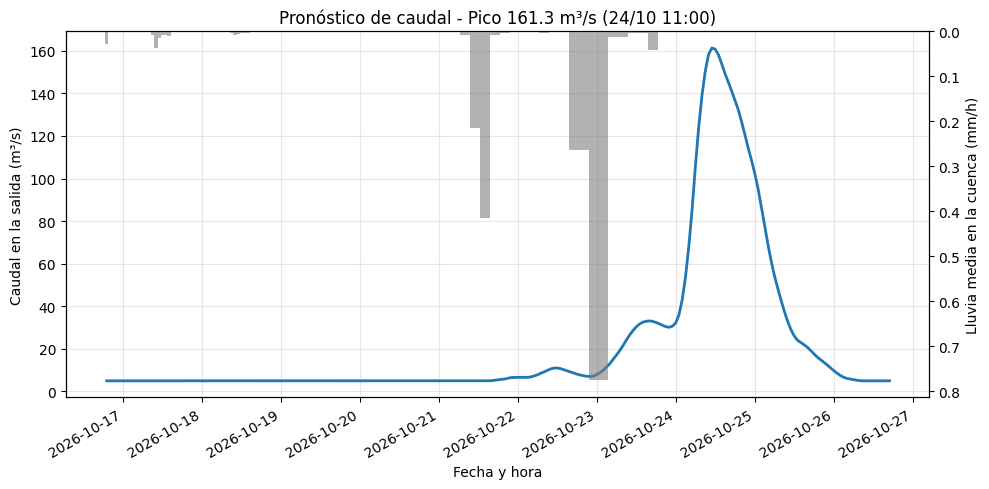

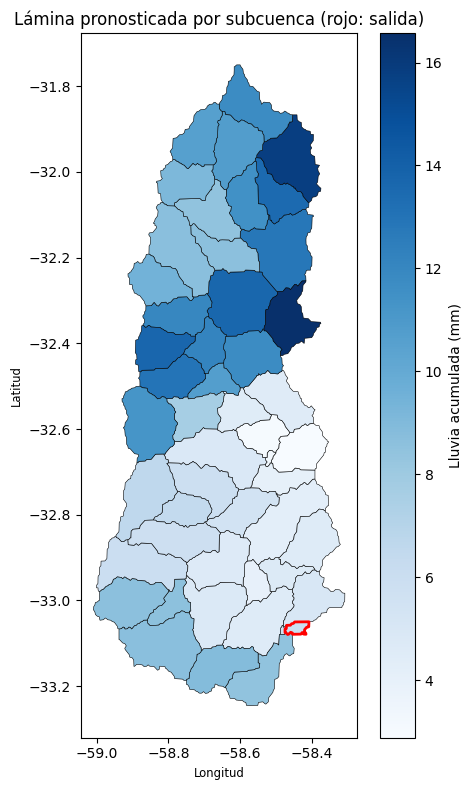

In [ ]:
# 6) Resultados: Excel, capa para QGIS y figuras
os.makedirs("resultados", exist_ok=True)
base = "resultados/pronostico_caudal_gualeguaychu"

pesos = subc.set_index("ID")["Area_km2"]
pe_med = float((R["pe"] * pesos).sum(axis=1).sum() / pesos.sum())
resumen = pd.DataFrame({
    "Parametro": ["Q pico en la salida (m3/s)", "Fecha/hora del pico",
                  "Subcuenca de salida (HYBAS_ID)", "Q base (m3/s)",
                  "Lluvia media acumulada en la cuenca (mm)",
                  "Lluvia efectiva media acumulada (mm)",
                  "Horas sin dato (rellenadas con 0)", "CN por defecto",
                  "Método Tc / pendiente (m/m)", "Velocidad de traslado (m/s)", "Ia/S"],
    "Valor": [round(q_pico, 2), str(t_pico), R["salida_id"], q_base,
              round(float(lluvia_media.sum()), 1), round(pe_med, 2),
              R["faltan"], cn_def, f"{metodo_tc} / {pendiente}", velocidad, ia_ratio]})

with pd.ExcelWriter(base + ".xlsx", engine="openpyxl") as xw:
    resumen.to_excel(xw, sheet_name="Resumen", index=False)
    q_sal.to_frame().join(lluvia_media.rename("Lluvia_media_mm")).to_excel(xw, sheet_name="Q_salida")
    R["lluvia"].to_excel(xw, sheet_name="Lluvia_subcuenca_mm")
    R["pe"].to_excel(xw, sheet_name="Lluvia_efectiva_mm")
    R["q_sub"].to_excel(xw, sheet_name="Q_subcuencas_m3s")
    subc.rename(columns={"ID": "HYBAS_ID"}).to_excel(xw, sheet_name="Parametros_subcuencas", index=False)

# Capa con lámina acumulada por subcuenca
g = R["gdf84"].copy()
g["Lluvia_mm"] = R["lluvia"].sum().values
g["Pe_mm"] = R["pe"].sum().values
g["Tc_h"] = subc["Tc_h"].values
g["Tv_h"] = subc["Tv_h"].values
g["CN_usado"] = subc["CN"].values
g.to_file(base + "_subcuencas.gpkg", driver="GPKG")

# Figura 1: hidrograma en el punto de descarga
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(q_sal.index, q_sal.values, color="tab:blue", lw=2)
ax.set_ylabel("Caudal en la salida (m³/s)")
ax.set_xlabel("Fecha y hora")
ax.grid(alpha=0.3)
ax2 = ax.twinx()
ax2.bar(lluvia_media.index, lluvia_media.values, width=1 / 24, color="tab:gray", alpha=0.6)
ax2.set_ylabel("Lluvia media en la cuenca (mm/h)")
ax2.invert_yaxis()
ax.set_title(f"Pronóstico de caudal - Pico {q_pico:.1f} m³/s ({t_pico:%d/%m %H:%M})")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(base + ".png", dpi=150)
plt.show()

# Figura 2: mapa de lámina acumulada por subcuenca
fig2, ax3 = plt.subplots(figsize=(5, 8))
g.plot(column="Lluvia_mm", cmap="Blues", legend=True, edgecolor="k", linewidth=0.4,
       ax=ax3, legend_kwds={"label": "Lluvia acumulada (mm)"})
g[g["HYBAS_ID"].astype(str) == R["salida_id"]].plot(ax=ax3, facecolor="none",
                                                     edgecolor="red", linewidth=2)
ax3.set_title("Lámina pronosticada por subcuenca (rojo: salida)")
ax3.set_xlabel("Longitud"); ax3.set_ylabel("Latitud")
fig2.tight_layout()
fig2.savefig(base + "_mapa.png", dpi=150)
plt.show()

In [ ]:
# 7) Descargar todo en un .zip
shutil.make_archive("resultados_pronostico", "zip", "resultados")
files.download("resultados_pronostico.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>